# DMS672: Data Mining — Assignment 4
## Exploratory Data Analysis (EDA) on the Titanic Dataset
### Goal: find out **which type of passengers were more likely to survive**

**Dataset:** `titanic_train.csv` (891 passengers, 12 attributes). Target column: `Survived` (1 = survived, 0 = did not).

**Notebook layout (mapped to the assignment tasks)**

| Section | Assignment task |
|---|---|
| 1. Attribute profiling | Task 1 — attributes, types, distinct values, mean, median, std, range |
| 2. Data preprocessing | Task 4 — cleaning, imputation, outliers, feature construction, transformation |
| 3. Plots & distributions | Task 2 — histogram, boxplot, scatter, QQ plot, etc. |
| 4. Who is more likely to survive? | Task 3 — survival EDA + statistical tests |
| 5. Summary | Final conclusions |

> **Note on order:** preprocessing (Task 4) is done *before* the plots and survival analysis so that Tasks 2 and 3 run on clean data (e.g. no missing `Age`).

## 0. Setup: imports and data loading

In [1]:
import glob, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

SURV_COLORS = {0: "#d9534f", 1: "#3c9d5d"}   # red = died, green = survived
print("Libraries loaded.")

Libraries loaded.


In [2]:
paths = glob.glob("titanic_train*.csv") + glob.glob("/mnt/user-data/uploads/titanic_train*.csv")
df = pd.read_csv(paths[0])
print("Loaded:", paths[0])
print("Shape :", df.shape)
df.head()

Loaded: titanic_train.csv
Shape : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


---
## 1. Attribute Profiling (Task 1)

For every attribute: its **data-mining type** (nominal / ordinal / binary / numeric), number of **distinct values**, and, for numeric attributes, **mean, median, standard deviation and range**.

In [ ]:
attr_type = {
    "PassengerId": "Identifier (nominal, no analytic value)",
    "Survived":    "Binary nominal (target)",
    "Pclass":      "Ordinal (1st > 2nd > 3rd class)",
    "Name":        "Nominal (text)",
    "Sex":         "Binary nominal",
    "Age":         "Numeric, ratio-scaled, continuous",
    "SibSp":       "Numeric, ratio-scaled, discrete (count)",
    "Parch":       "Numeric, ratio-scaled, discrete (count)",
    "Ticket":      "Nominal (alphanumeric code)",
    "Fare":        "Numeric, ratio-scaled, continuous",
    "Cabin":       "Nominal (alphanumeric code)",
    "Embarked":    "Nominal (C = Cherbourg, Q = Queenstown, S = Southampton)",
}
attr_info = pd.DataFrame({
    "Attribute": df.columns,
    "Pandas dtype": df.dtypes.astype(str).values,
    "Attribute type": [attr_type[c] for c in df.columns],
    "Non-null": df.notnull().sum().values,
    "Missing": df.isnull().sum().values,
    "Distinct values": df.nunique().values,
}).set_index("Attribute")
attr_info

,Pandas dtype,Attribute type,Non-null,Missing,Distinct values
Attribute,,,,,
PassengerId,int64,"Identifier (nominal, no analytic value)",891,0,891
Survived,int64,Binary nominal (target),891,0,2
Pclass,int64,Ordinal (1st > 2nd > 3rd class),891,0,3
Name,str,Nominal (text),891,0,891
Sex,str,Binary nominal,891,0,2
Age,float64,"Numeric, ratio-scaled, continuous",714,177,88
SibSp,int64,"Numeric, ratio-scaled, discrete (count)",891,0,7
Parch,int64,"Numeric, ratio-scaled, discrete (count)",891,0,7
Ticket,str,Nominal (alphanumeric code),891,0,681


### 1.1 Numeric attributes: mean, median, standard deviation, range

In [4]:
num_cols = ["PassengerId", "Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
summary = df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
summary["range (max-min)"] = summary["max"] - summary["min"]
summary.round(3)

,count,mean,median,std,min,max,range (max-min)
PassengerId,891.0,446.000,446.000,257.354,1.00,891.000,890.000
Survived,891.0,0.384,0.000,0.487,0.00,1.000,1.000
Pclass,891.0,2.309,3.000,0.836,1.00,3.000,2.000
Age,714.0,29.699,28.000,14.526,0.42,80.000,79.580
SibSp,891.0,0.523,0.000,1.103,0.00,8.000,8.000
Parch,891.0,0.382,0.000,0.806,0.00,6.000,6.000
Fare,891.0,32.204,14.454,49.693,0.00,512.329,512.329


### 1.2 Distinct values of low-cardinality attributes

In [ ]:
for c in ["Survived", "Pclass", "Sex", "SibSp", "Parch", "Embarked"]:
    vc = df[c].value_counts(dropna=False).sort_index()
    print(f"{c:9s} -> {df[c].nunique()} distinct (excl. NaN): {dict(vc)}")
print()
for c in ["Name", "Ticket", "Cabin"]:
    print(f"{c:9s} -> {df[c].nunique()} distinct values | most frequent: {df[c].mode()[0]!r} "
          f"({df[c].value_counts().iloc[0]} times) | missing: {df[c].isnull().sum()}")

Survived  -> 2 distinct (excl. NaN): {0: np.int64(549), 1: np.int64(342)}
Pclass    -> 3 distinct (excl. NaN): {1: np.int64(216), 2: np.int64(184), 3: np.int64(491)}
Sex       -> 2 distinct (excl. NaN): {'female': np.int64(314), 'male': np.int64(577)}
SibSp     -> 7 distinct (excl. NaN): {0: np.int64(608), 1: np.int64(209), 2: np.int64(28), 3: np.int64(16), 4: np.int64(18), 5: np.int64(5), 8: np.int64(7)}
Parch     -> 7 distinct (excl. NaN): {0: np.int64(678), 1: np.int64(118), 2: np.int64(80), 3: np.int64(5), 4: np.int64(4), 5: np.int64(5), 6: np.int64(1)}
Embarked  -> 3 distinct (excl. NaN): {'C': np.int64(168), 'Q': np.int64(77), 'S': np.int64(644), nan: np.int64(2)}

Name      -> 891 distinct values | most frequent: 'Abbing, Mr. Anthony' (1 times) | missing: 0
Ticket    -> 681 distinct values | most frequent: '1601' (7 times) | missing: 0
Cabin     -> 147 distinct values | most frequent: 'B96 B98' (4 times) | missing: 687


### 1.3 Data-quality check on the raw data (missing values and duplicates)

          Missing  Missing %
Age           177      19.87
Cabin         687      77.10
Embarked        2       0.22

Duplicate rows       : 0
Duplicate PassengerIds: 0
Passengers with Fare == 0: 15
Infants (Age < 1)    : 7


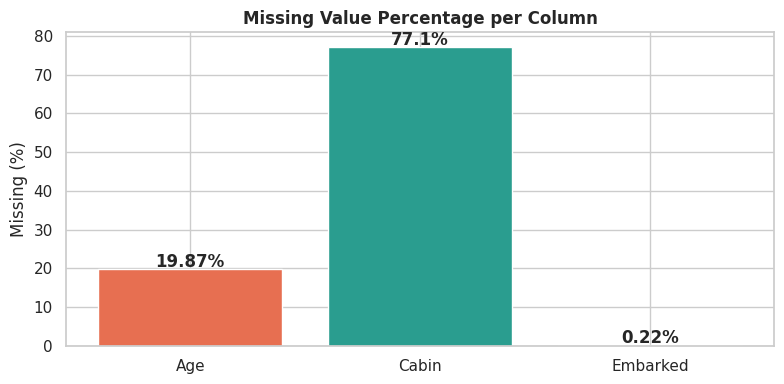

In [7]:
# Missing value analysis

missing_df = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

# Keep only columns having missing values
missing_df = missing_df[missing_df["Missing"] > 0]

print(missing_df)

print("\nDuplicate rows       :", df.duplicated().sum())
print("Duplicate PassengerIds:", df["PassengerId"].duplicated().sum())
print("Passengers with Fare == 0:", (df["Fare"] == 0).sum())
print("Infants (Age < 1)    :", (df["Age"] < 1).sum())


# Visualise
plt.figure(figsize=(8, 4))

bars = plt.bar(
    missing_df.index,
    missing_df["Missing %"],
    color=['#E76F51', '#2A9D8F', '#264653'],
    edgecolor='white'
)

plt.title("Missing Value Percentage per Column", fontweight='bold')
plt.ylabel("Missing (%)")

# Add percentage labels
for bar, val in zip(bars, missing_df["Missing %"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{val}%',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

**Observations (raw data)**
- `Cabin` is missing for ~77% of passengers, `Age` for ~20%, `Embarked` for only 2 rows.
- No duplicate rows / IDs. A few passengers have `Fare = 0` (probably crew or complimentary tickets), a data-integrity flag we keep in mind but do not delete.
- The data is therefore *not clean*, which motivates Section 2.

---
## 2. Data Preprocessing (Task 4, Chapter 3 concepts)

Chapter 3 pipeline followed here: **(a) data cleaning** → missing values, duplicates, outliers → **(b) attribute construction** → **(c) data reduction** → **(d) data transformation** (normalisation, discretisation, encoding).

We keep the raw `df` untouched and work on `df_clean`.

### 2.1 Handling missing values

| Attribute | Missing | Strategy | Reason |
|---|---|---|---|
| `Cabin` | 687 (77%) | Extract the **deck letter**, unknown → `"Unknown"`, then drop `Cabin` | Too sparse to impute; the deck letter keeps the useful signal (and "Unknown" itself is informative) |
| `Age` | 177 (20%) | Fill with **median of the passenger's (`Pclass`, `Sex`) group** | Age differs strongly by class and sex, so a group median is more faithful than one global value; median is robust to outliers |
| `Embarked` | 2 | Fill with the **mode** | Nominal attribute with only 2 gaps |

In [10]:
df_clean = df.copy()

print("Missing BEFORE:")
print(df_clean[["Cabin", "Age", "Embarked"]].isnull().sum(), "\n")

# ---- Cabin -> Deck -----------------------------------------------------------
df_clean["Deck"] = df_clean["Cabin"].apply(lambda x: x[0] if pd.notnull(x) else "Unknown")
df_clean.drop(columns=["Cabin"], inplace=True)

# ---- Age: median by (Pclass, Sex) --------------------------------------------
print("Median Age used for imputation (Pclass x Sex):")
print(df_clean.groupby(["Pclass", "Sex"])["Age"].median().unstack().round(1), "\n")

df_clean["Age"] = df_clean.groupby(["Pclass", "Sex"])["Age"].transform(
    lambda x: x.fillna(x.median()))
print("Missing Age after:", df_clean["Age"].isnull().sum())      # -> 0

# ---- Embarked: mode ----------------------------------------------------------
print("Embarked mode:", df_clean["Embarked"].mode()[0])
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])
print("Missing Embarked after:", df_clean["Embarked"].isnull().sum())

print("\nMissing AFTER (whole dataset):")
print(df_clean.isnull().sum()[lambda s: s > 0] if df_clean.isnull().sum().sum() else "No missing values left")

Missing BEFORE:
Cabin       687
Age         177
Embarked      2
dtype: int64 

Median Age used for imputation (Pclass x Sex):
Sex     female  male
Pclass              
1         35.0  40.0
2         28.0  30.0
3         21.5  25.0 

Missing Age after: 0
Embarked mode: S
Missing Embarked after: 0

Missing AFTER (whole dataset):
No missing values left


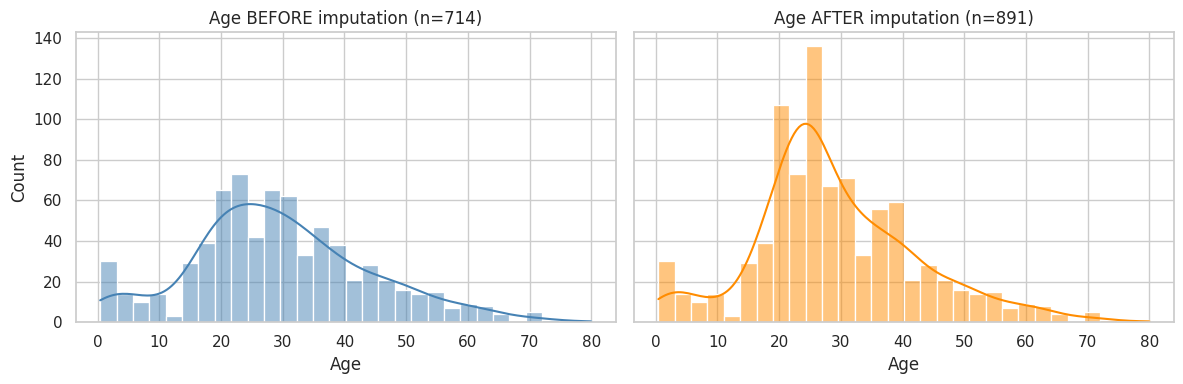

Mean   : 29.70 -> 29.11
Median : 28.00 -> 26.00
Std    : 14.53 -> 13.30


In [ ]:
# Did the Age imputation distort the distribution?
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(df["Age"].dropna(), bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title(f"Age BEFORE imputation (n={df['Age'].notnull().sum()})")
sns.histplot(df_clean["Age"], bins=30, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title(f"Age AFTER imputation (n={len(df_clean)})")
plt.tight_layout(); plt.show()

print(f"Mean   : {df['Age'].mean():.2f} -> {df_clean['Age'].mean():.2f}")
print(f"Median : {df['Age'].median():.2f} -> {df_clean['Age'].median():.2f}")
print(f"Std    : {df['Age'].std():.2f} -> {df_clean['Age'].std():.2f}")

The mean moves by about half a year and the median by about two years, and the standard deviation shrinks (expected, because imputed values sit at group medians). The overall shape of the distribution is preserved, so the group-median imputation is acceptable.

### 2.2 Duplicates and inconsistent values

In [11]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Invalid Survived values:", (~df_clean.Survived.isin([0, 1])).sum())
print("Invalid Pclass values  :", (~df_clean.Pclass.isin([1, 2, 3])).sum())
print("Negative Age/Fare      :", ((df_clean.Age < 0) | (df_clean.Fare < 0)).sum())
print("Sex categories         :", df_clean.Sex.unique())
print("Embarked categories    :", df_clean.Embarked.unique())
print("Fare == 0 rows         :", (df_clean.Fare == 0).sum(), "(kept: plausible free/crew tickets)")

Duplicate rows: 0
Invalid Survived values: 0
Invalid Pclass values  : 0
Negative Age/Fare      : 0
Sex categories         : ['male' 'female']
Embarked categories    : ['S' 'C' 'Q']
Fare == 0 rows         : 15 (kept: plausible free/crew tickets)


### 2.3 Outlier detection (IQR rule)

Age   : fences [  -0.25,   57.75] ->  33 outliers ( 3.7%)
Fare  : fences [ -26.72,   65.63] -> 116 outliers (13.0%)
SibSp : fences [  -1.50,    2.50] ->  46 outliers ( 5.2%)
Parch : fences [   0.00,    0.00] -> 213 outliers (23.9%)


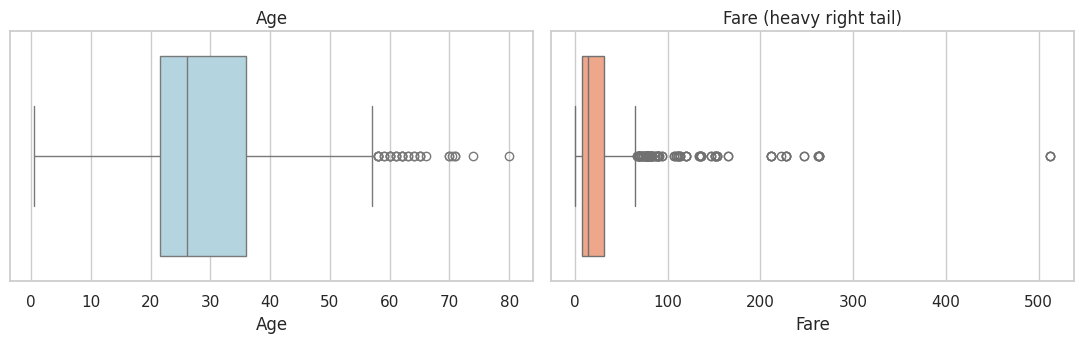

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, ((s < lo) | (s > hi)).sum()

for col in ["Age", "Fare", "SibSp", "Parch"]:
    lo, hi, n = iqr_outliers(df_clean[col])
    print(f"{col:6s}: fences [{lo:7.2f}, {hi:7.2f}] -> {n:3d} outliers ({n/len(df_clean)*100:4.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=df_clean["Age"], color="lightblue", ax=axes[0]); axes[0].set_title("Age")
sns.boxplot(x=df_clean["Fare"], color="lightsalmon", ax=axes[1]); axes[1].set_title("Fare (heavy right tail)")
plt.tight_layout(); plt.show()

**Decision:** the `Fare` outliers are genuine (very expensive first-class suites, up to ≈ £512) and `Age` outliers are genuine elderly passengers, so **we do not delete them**. Instead we tame the skew of `Fare` with a **log transform** (and keep a 99th-percentile capped version for reference).

In [13]:
df_clean["Fare_log"] = np.log1p(df_clean["Fare"])                              # log(1 + Fare) handles Fare = 0
df_clean["Fare_capped"] = df_clean["Fare"].clip(upper=df_clean["Fare"].quantile(0.99))

print(f"Skewness of Fare        : {df_clean['Fare'].skew():.2f}")
print(f"Skewness of Fare_capped : {df_clean['Fare_capped'].skew():.2f}")
print(f"Skewness of Fare_log    : {df_clean['Fare_log'].skew():.2f}")

Skewness of Fare        : 4.79
Skewness of Fare_capped : 3.11
Skewness of Fare_log    : 0.39


### 2.4 Attribute (feature) construction and discretisation

In [14]:
# Title extracted from Name (Mr, Mrs, Miss, Master, ...)
df_clean["Title"] = df_clean["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
df_clean["Title"] = df_clean["Title"].replace(title_map)
main_titles = ["Mr", "Mrs", "Miss", "Master"]
df_clean["Title"] = df_clean["Title"].where(df_clean["Title"].isin(main_titles), "Rare")

# Family features
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1
df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)

# Discretisation: Age -> ordered age groups, Fare -> quartile bands
df_clean["AgeGroup"] = pd.cut(df_clean["Age"], bins=[0, 12, 18, 35, 60, 100],
                              labels=["Child (0-12)", "Teen (13-18)", "Young adult (19-35)",
                                      "Adult (36-60)", "Senior (60+)"])
df_clean["FareBand"] = pd.qcut(df_clean["Fare"], q=4, labels=["Low", "Medium", "High", "Very high"])

print(df_clean["Title"].value_counts(), "\n")
print(df_clean["AgeGroup"].value_counts().sort_index(), "\n")
print(df_clean["FareBand"].value_counts().sort_index())
df_clean[["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone", "Age", "AgeGroup", "Fare", "FareBand", "Deck"]].head(8)

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64 

AgeGroup
Child (0-12)            69
Teen (13-18)            70
Young adult (19-35)    514
Adult (36-60)          216
Senior (60+)            22
Name: count, dtype: int64 

FareBand
Low          223
Medium       224
High         222
Very high    222
Name: count, dtype: int64


,Name,Title,SibSp,Parch,FamilySize,IsAlone,Age,AgeGroup,Fare,FareBand,Deck
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0,22.0,Young adult (19-35),7.2500,Low,Unknown
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0,38.0,Adult (36-60),71.2833,Very high,C
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1,26.0,Young adult (19-35),7.9250,Medium,Unknown
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0,35.0,Young adult (19-35),53.1000,Very high,C
4,"Allen, Mr. William Henry",Mr,0,0,1,1,35.0,Young adult (19-35),8.0500,Medium,Unknown
5,"Moran, Mr. James",Mr,0,0,1,1,25.0,Young adult (19-35),8.4583,Medium,Unknown
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1,54.0,Adult (36-60),51.8625,Very high,E
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0,2.0,Child (0-12),21.0750,High,Unknown


### 2.5 Data reduction and transformation (for modelling)

- **Reduction:** drop `PassengerId`, `Name`, `Ticket` (identifiers / free text with no generalisable signal; the useful part of `Name` is already in `Title`) and the raw/derived duplicates of the same information (`Fare`, `Fare_capped`, `SibSp`+`Parch` kept only through `FamilySize`, plus the discretised versions).
- **Transformation:** `Sex` → binary, nominal attributes → one-hot, numeric attributes → **z-score** normalisation (and min-max shown for comparison).

In [15]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

df_model = df_clean.drop(columns=["PassengerId", "Name", "Ticket", "Fare", "Fare_capped",
                                  "AgeGroup", "FareBand", "SibSp", "Parch"]).copy()

# binary encoding
df_model["Is_Female"] = (df_model["Sex"] == "female").astype(int)
df_model.drop(columns="Sex", inplace=True)

# one-hot encoding of nominal attributes
df_model = pd.get_dummies(df_model, columns=["Embarked", "Title", "Deck"], dtype=int)

# normalisation
scale_cols = ["Age", "Fare_log", "FamilySize"]
z = StandardScaler().fit_transform(df_model[scale_cols])
mm = MinMaxScaler().fit_transform(df_model[scale_cols])
print("Z-score  -> mean ~ 0, std ~ 1 :", np.round(z.mean(0), 3), np.round(z.std(0), 3))
print("Min-max  -> range [0, 1]      :", mm.min(0), mm.max(0))

df_model[scale_cols] = z          # keep z-scores in the modelling table
print("\nFinal modelling table:", df_model.shape)
print("Missing values left  :", df_model.isnull().sum().sum())
df_model.head()

Z-score  -> mean ~ 0, std ~ 1 : [ 0. -0. -0.] [1. 1. 1.]
Min-max  -> range [0, 1]      : [0. 0. 0.] [1. 1. 1.]

Final modelling table: (891, 24)
Missing values left  : 0


,Survived,Pclass,Age,Fare_log,FamilySize,IsAlone,Is_Female,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown
0,0,3,-0.534891,-0.879741,0.059160,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1
1,1,1,0.668392,1.361220,0.059160,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0
2,1,3,-0.234070,-0.798540,-0.560975,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1
3,1,1,0.442776,1.062038,0.059160,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0
4,0,3,0.442776,-0.784179,-0.560975,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1


In [16]:
print("Final EDA table (df_clean):", df_clean.shape, "| missing values:", df_clean.isnull().sum().sum())
df_clean.info()

Final EDA table (df_clean): (891, 19) | missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    object  
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    object  
 11  Deck         891 non-null    object  
 12  Fare_log     891 non-null    float64 
 13  Fare_capped  891 non-null    float64 
 14  Title        891 non-null    object  
 15  FamilySize   891 non-null    int64   
 16  IsAlone      891 non-null    int64   
 17  AgeGroup     89

---
## 3. Plots and Distributions (Task 2)

Chapter-2 style visualisations: **histogram, boxplot, bar/pie chart, QQ plot, scatter plot, correlation heatmap, pair plot**, with a check of the distribution of each attribute.

### 3.1 Histograms with density curves (numeric attributes)

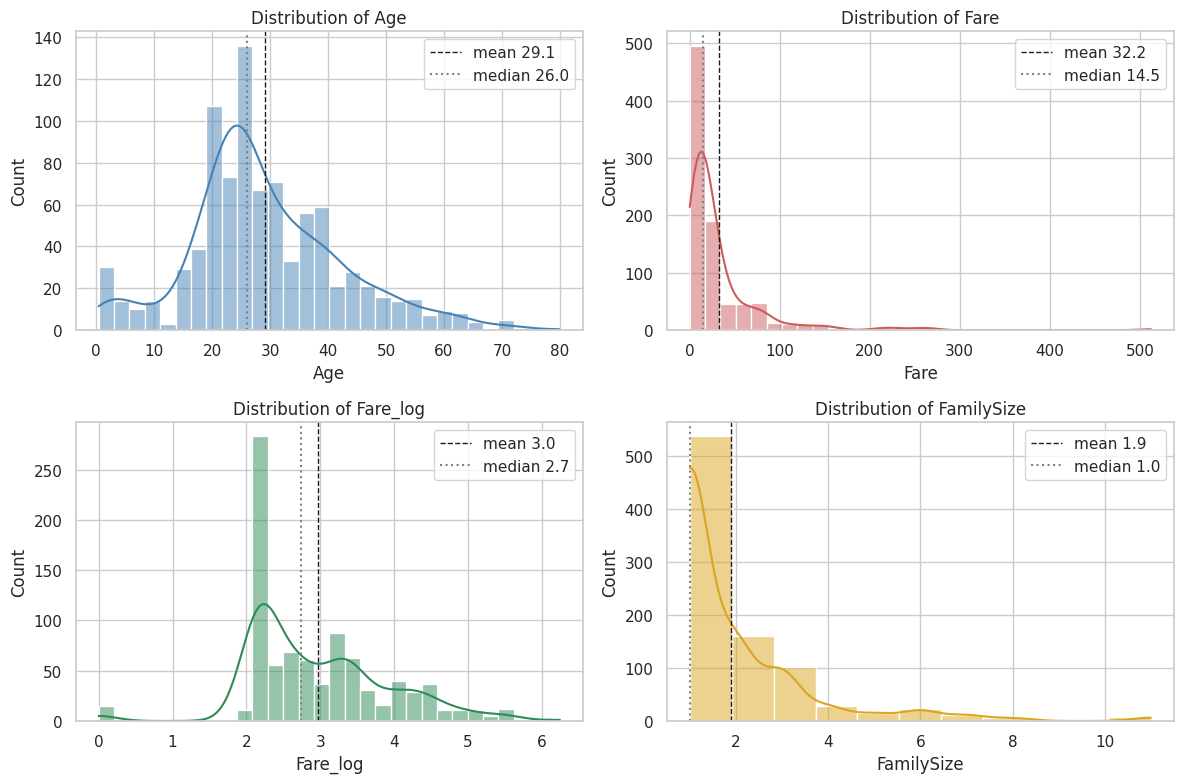

,skewness,kurtosis,shape
Age,0.53,0.72,"roughly symmetric, slight right skew"
Fare,4.79,33.40,very strongly right-skewed
Fare_log,0.39,0.98,much closer to symmetric after log
FamilySize,2.73,9.16,right-skewed (most travel alone)


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, color in zip(axes.ravel(), ["Age", "Fare", "Fare_log", "FamilySize"],
                          ["steelblue", "indianred", "seagreen", "goldenrod"]):
    sns.histplot(df_clean[col], bins=30 if col != "FamilySize" else 11, kde=True, color=color, ax=ax)
    ax.axvline(df_clean[col].mean(), color="k", ls="--", lw=1, label=f"mean {df_clean[col].mean():.1f}")
    ax.axvline(df_clean[col].median(), color="gray", ls=":", lw=1.5, label=f"median {df_clean[col].median():.1f}")
    ax.set_title(f"Distribution of {col}"); ax.legend()
plt.tight_layout(); plt.show()

dist = pd.DataFrame({"skewness": df_clean[["Age", "Fare", "Fare_log", "FamilySize"]].skew(),
                     "kurtosis": df_clean[["Age", "Fare", "Fare_log", "FamilySize"]].kurt()}).round(2)
dist["shape"] = ["roughly symmetric, slight right skew", "very strongly right-skewed",
                 "much closer to symmetric after log", "right-skewed (most travel alone)"]
dist

### 3.2 Boxplots

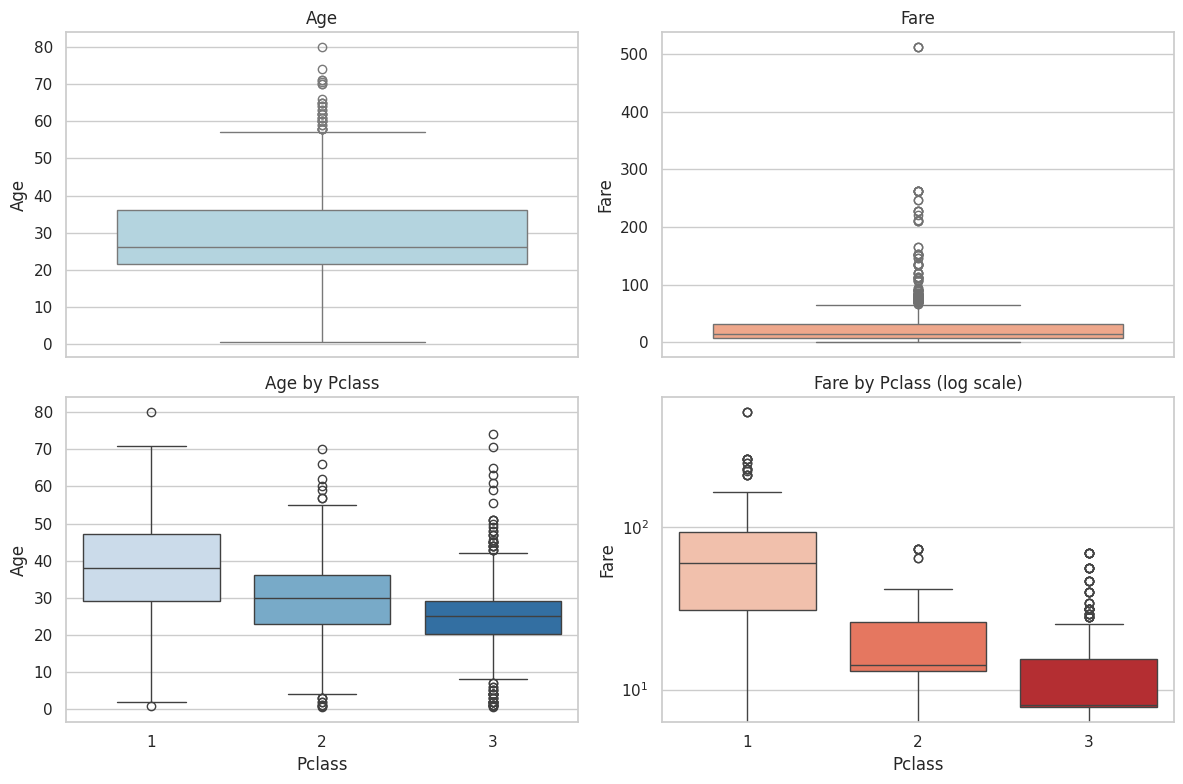

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.boxplot(data=df_clean, y="Age", color="lightblue", ax=axes[0, 0]); axes[0, 0].set_title("Age")
sns.boxplot(data=df_clean, y="Fare", color="lightsalmon", ax=axes[0, 1]); axes[0, 1].set_title("Fare")
sns.boxplot(data=df_clean, x="Pclass", y="Age", palette="Blues", ax=axes[1, 0]); axes[1, 0].set_title("Age by Pclass")
sns.boxplot(data=df_clean, x="Pclass", y="Fare", palette="Reds", ax=axes[1, 1])
axes[1, 1].set_yscale("log"); axes[1, 1].set_title("Fare by Pclass (log scale)")
plt.tight_layout(); plt.show()

First-class passengers are older on average and pay far more; the fare distribution is dominated by a long tail of expensive tickets.

### 3.3 Categorical attributes: bar charts and pie chart

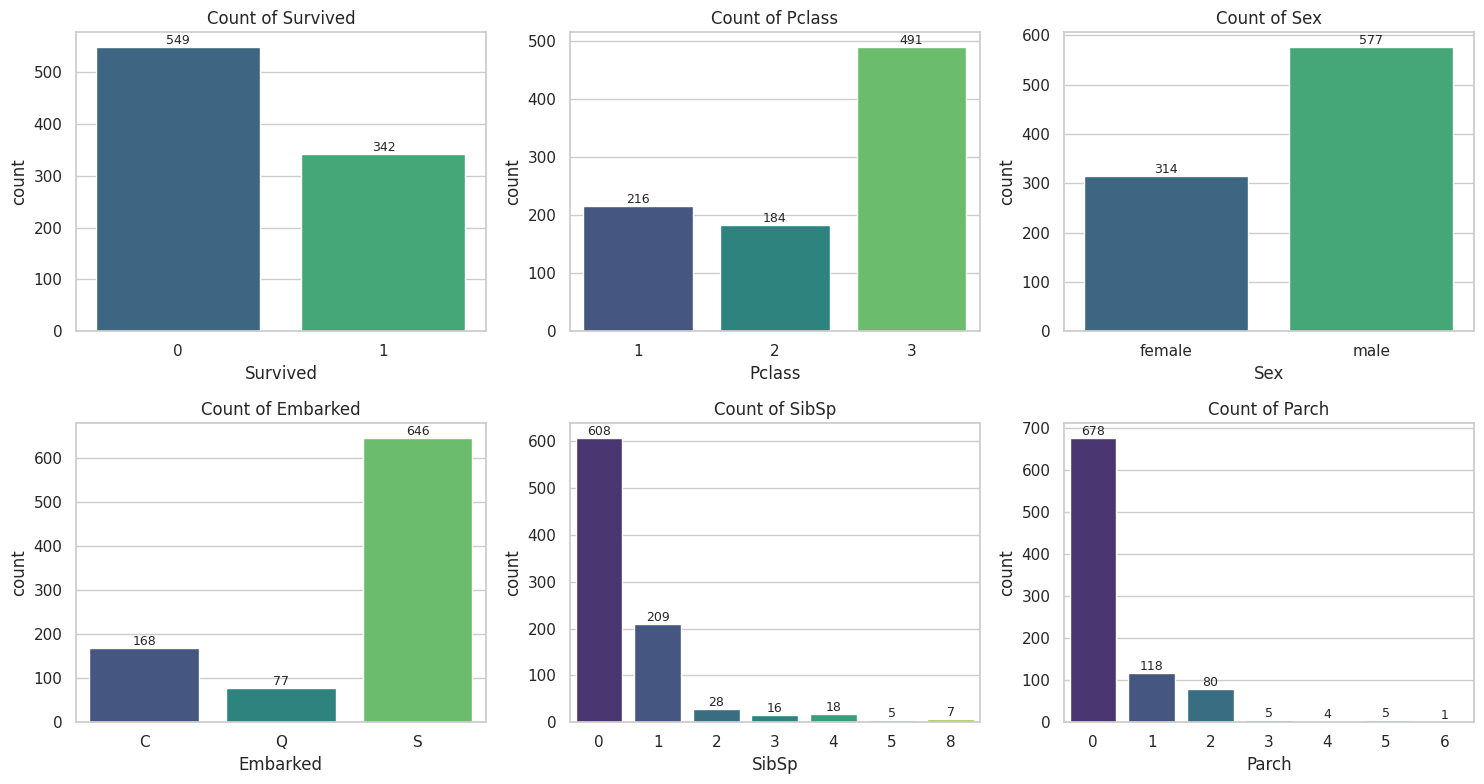

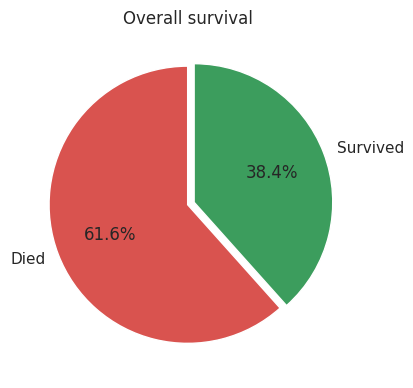

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["Survived", "Pclass", "Sex", "Embarked", "SibSp", "Parch"]):
    order = sorted(df_clean[col].unique())
    sns.countplot(data=df_clean, x=col, order=order, palette="viridis", ax=ax)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Count of {col}")
plt.tight_layout(); plt.show()

plt.figure(figsize=(4.5, 4.5))
df_clean["Survived"].map({0: "Died", 1: "Survived"}).value_counts().plot.pie(
    autopct="%1.1f%%", colors=["#d9534f", "#3c9d5d"], startangle=90, explode=[0, 0.05])
plt.ylabel(""); plt.title("Overall survival"); plt.show()

### 3.4 QQ plots and normality tests

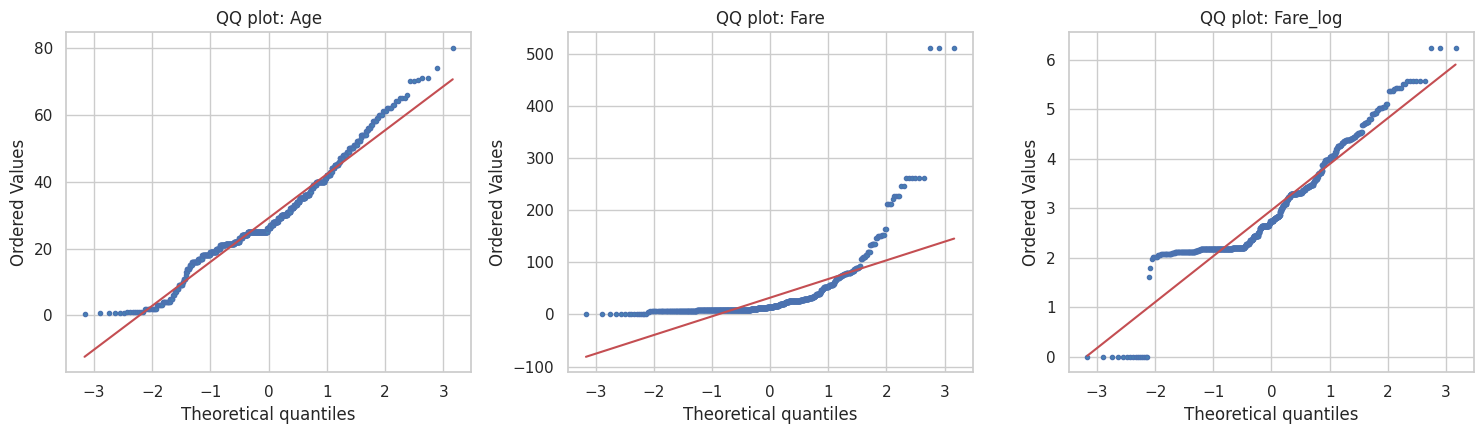

Shapiro-Wilk normality test (H0: data is normal)
  Age       W = 0.9655, p = 1.12e-13 -> reject normality
  Fare      W = 0.5219, p = 1.08e-43 -> reject normality
  Fare_log  W = 0.9152, p = 6.64e-22 -> reject normality


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["Age", "Fare", "Fare_log"]):
    stats.probplot(df_clean[col], dist="norm", plot=ax)
    ax.set_title(f"QQ plot: {col}")
    ax.get_lines()[0].set_markerfacecolor("steelblue"); ax.get_lines()[0].set_markersize(3)
plt.tight_layout(); plt.show()

print("Shapiro-Wilk normality test (H0: data is normal)")
for col in ["Age", "Fare", "Fare_log"]:
    w, p = stats.shapiro(df_clean[col])
    print(f"  {col:9s} W = {w:.4f}, p = {p:.2e} -> {'reject' if p < 0.05 else 'fail to reject'} normality")

- **Age:** the QQ plot follows the line in the middle but bends at the tails (an excess of very young children and a spike at the imputed median), so it is *approximately* but not perfectly normal.
- **Fare:** the QQ plot curves sharply away from the line, confirming a heavy right skew.
- **log(Fare):** much closer to the line: the log transform fixes most of the skew.

### 3.5 Scatter plots

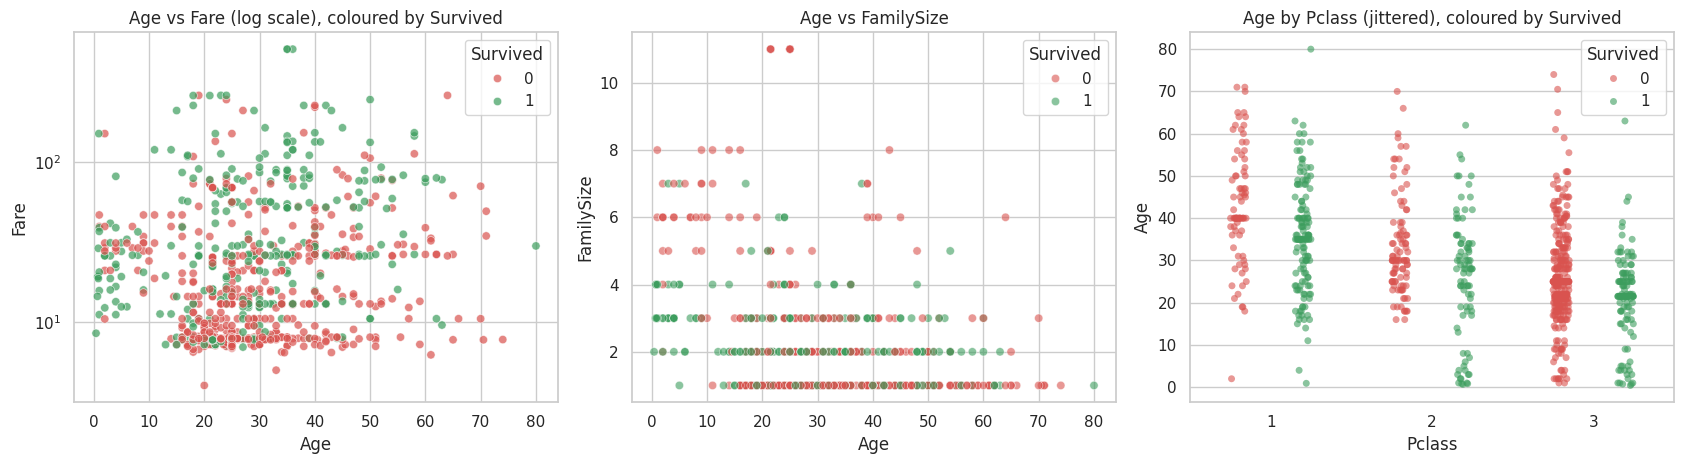

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.scatterplot(data=df_clean, x="Age", y="Fare", hue="Survived", palette=SURV_COLORS, alpha=0.7, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Age vs Fare (log scale), coloured by Survived")

sns.scatterplot(data=df_clean, x="Age", y="FamilySize", hue="Survived", palette=SURV_COLORS, alpha=0.6, ax=axes[1])
axes[1].set_title("Age vs FamilySize")

sns.stripplot(data=df_clean, x="Pclass", y="Age", hue="Survived", palette=SURV_COLORS, dodge=True, alpha=0.6, ax=axes[2])
axes[2].set_title("Age by Pclass (jittered), coloured by Survived")
plt.tight_layout(); plt.show()

### 3.6 Correlation heatmap and pair plot

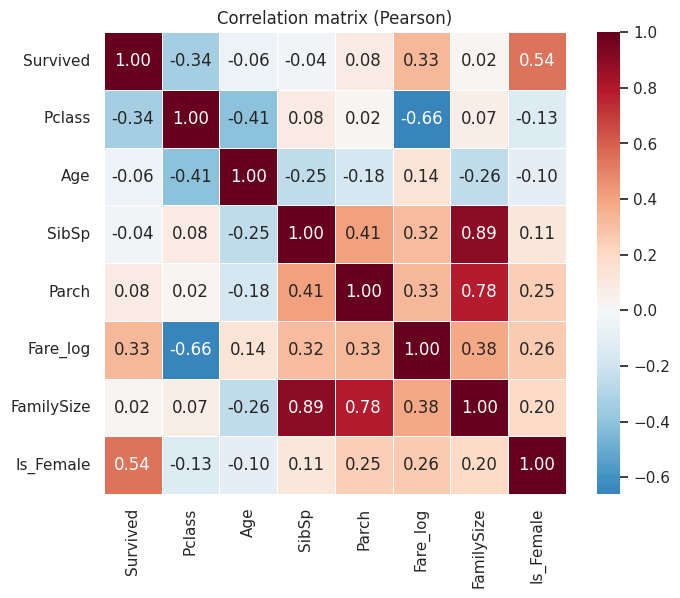

Correlation of each attribute with Survived:
Is_Female     0.543
Pclass       -0.338
Fare_log      0.330
Parch         0.082
Age          -0.060
SibSp        -0.035
FamilySize    0.017
Name: Survived, dtype: float64


In [22]:
num_for_corr = df_clean[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare_log", "FamilySize"]].copy()
num_for_corr["Is_Female"] = (df_clean["Sex"] == "female").astype(int)
corr = num_for_corr.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, linewidths=.5)
plt.title("Correlation matrix (Pearson)"); plt.show()

print("Correlation of each attribute with Survived:")
print(corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3))

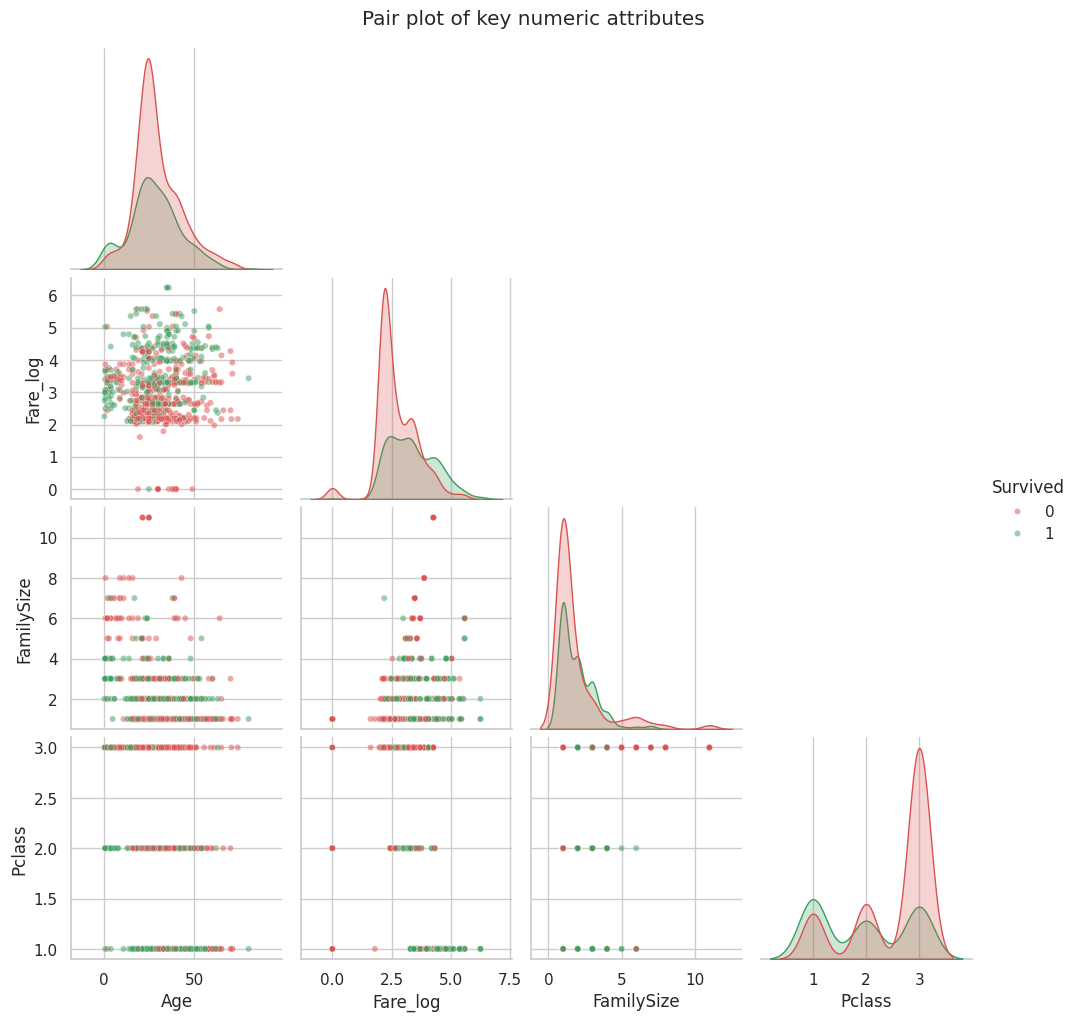

In [23]:
g = sns.pairplot(df_clean[["Survived", "Age", "Fare_log", "FamilySize", "Pclass"]],
                 hue="Survived", palette=SURV_COLORS, corner=True, plot_kws={"alpha": 0.5, "s": 20})
g.figure.suptitle("Pair plot of key numeric attributes", y=1.02)
plt.show()

**What Task 2 tells us about the distributions**
- `Age` ≈ unimodal, mildly right-skewed; `Fare` extremely right-skewed (fixed by log); `SibSp`, `Parch`, `FamilySize` are count variables concentrated at 0/1.
- Most passengers are 3rd class, male, embarked at Southampton and travelled alone.
- Strongest linear relationships with survival: **sex** (positive for female), **Pclass** (negative) and **Fare** (positive), the same variables that dominate Section 4.

---
## 4. Which Type of Passengers Were More Likely to Survive? (Task 3)

Approach: (1) overall survival rate → (2) survival rate by each attribute → (3) two-way interactions → (4) statistical significance tests → (5) a quick multivariate model as a cross-check → (6) profile of the safest and most at-risk groups.

### 4.1 Overall survival

In [24]:
n_surv = int(df_clean["Survived"].sum()); n_tot = len(df_clean)
overall = df_clean["Survived"].mean() * 100
print(f"{n_surv} of {n_tot} passengers survived -> overall survival rate = {overall:.1f}%")

342 of 891 passengers survived -> overall survival rate = 38.4%


### 4.2 Survival rate by individual attributes

In [25]:
def survival_table(col):
    t = df_clean.groupby(col, observed=True)["Survived"].agg(Survivors="sum", Passengers="count")
    t["Survival rate (%)"] = (t["Survivors"] / t["Passengers"] * 100).round(1)
    return t

for col in ["Sex", "Pclass", "AgeGroup", "Embarked"]:
    print(f"--- {col} ---")
    print(survival_table(col), "\n")

--- Sex ---
        Survivors  Passengers  Survival rate (%)
Sex                                             
female        233         314               74.2
male          109         577               18.9 

--- Pclass ---
        Survivors  Passengers  Survival rate (%)
Pclass                                          
1             136         216               63.0
2              87         184               47.3
3             119         491               24.2 

--- AgeGroup ---
                     Survivors  Passengers  Survival rate (%)
AgeGroup                                                     
Child (0-12)                40          69               58.0
Teen (13-18)                30          70               42.9
Young adult (19-35)        184         514               35.8
Adult (36-60)               83         216               38.4
Senior (60+)                 5          22               22.7 

--- Embarked ---
          Survivors  Passengers  Survival rate (%)
Embarke

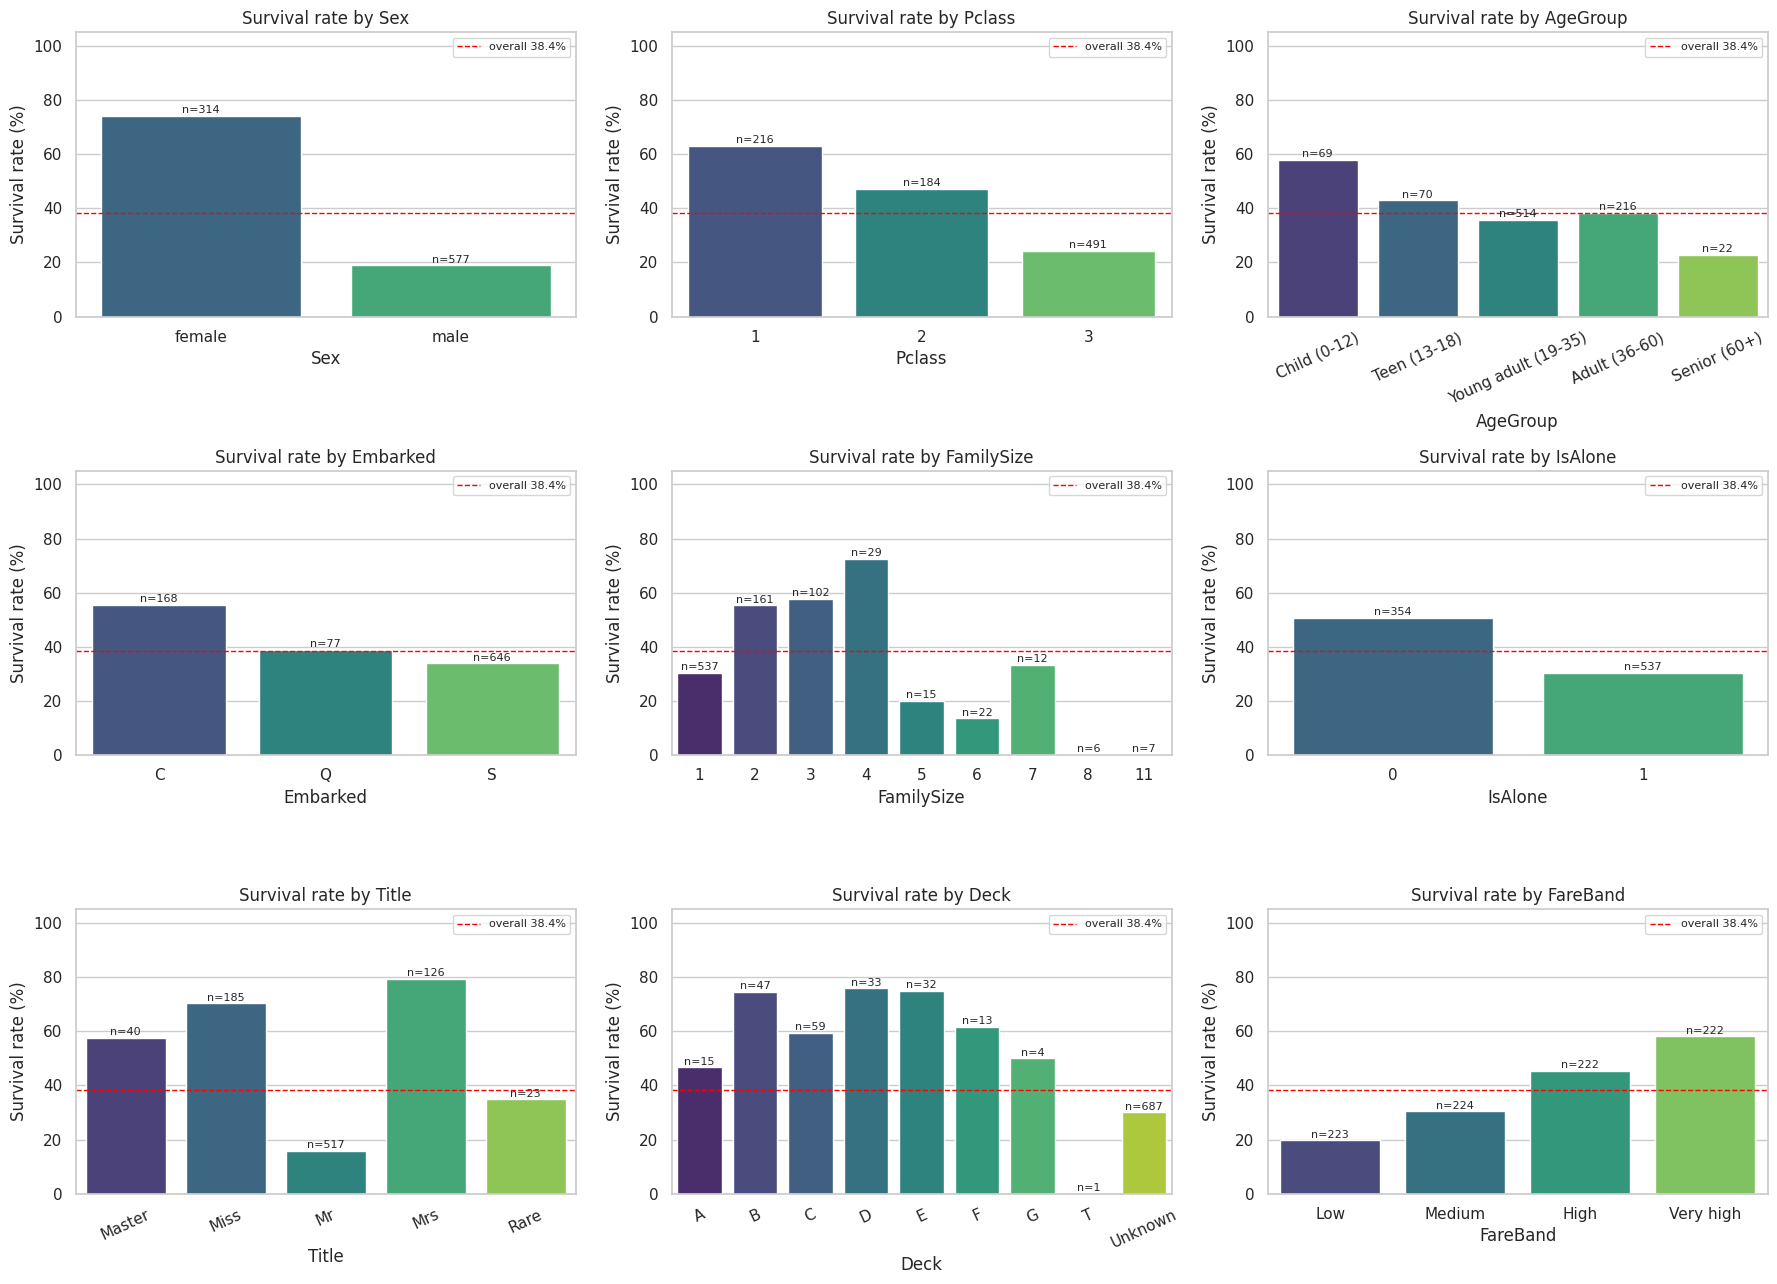

In [26]:
cols = ["Sex", "Pclass", "AgeGroup", "Embarked", "FamilySize", "IsAlone", "Title", "Deck", "FareBand"]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.ravel(), cols):
    t = survival_table(col).reset_index()
    sns.barplot(data=t, x=col, y="Survival rate (%)", palette="viridis", ax=ax)
    ax.axhline(overall, color="red", ls="--", lw=1, label=f"overall {overall:.1f}%")
    for i, r in t.iterrows():
        ax.text(i, r["Survival rate (%)"] + 1, f"n={int(r['Passengers'])}", ha="center", fontsize=8)
    ax.set_ylim(0, 105); ax.set_title(f"Survival rate by {col}"); ax.legend(loc="upper right", fontsize=8)
    if col in ("AgeGroup", "Deck", "Title"): ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

In [27]:
for col in ["FamilySize", "IsAlone", "Title", "Deck", "FareBand"]:
    print(f"--- {col} ---")
    print(survival_table(col), "\n")

--- FamilySize ---
            Survivors  Passengers  Survival rate (%)
FamilySize                                          
1                 163         537               30.4
2                  89         161               55.3
3                  59         102               57.8
4                  21          29               72.4
5                   3          15               20.0
6                   3          22               13.6
7                   4          12               33.3
8                   0           6                0.0
11                  0           7                0.0 

--- IsAlone ---
         Survivors  Passengers  Survival rate (%)
IsAlone                                          
0              179         354               50.6
1              163         537               30.4 

--- Title ---
        Survivors  Passengers  Survival rate (%)
Title                                           
Master         23          40               57.5
Miss          130

### 4.3 Two-way interactions

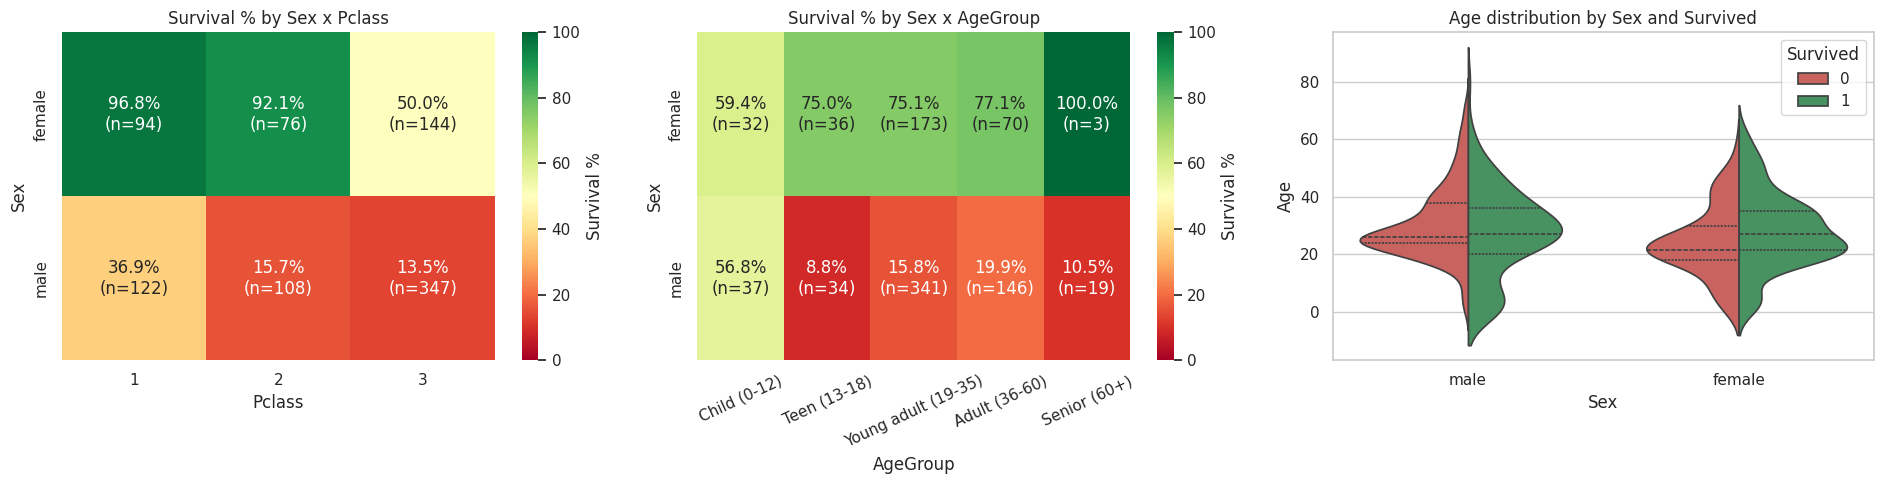

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

pt = df_clean.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean") * 100
cnt = df_clean.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="count")
labels = pt.round(1).astype(str) + "%\n(n=" + cnt.astype(str) + ")"
sns.heatmap(pt, annot=labels, fmt="", cmap="RdYlGn", vmin=0, vmax=100, ax=axes[0], cbar_kws={"label": "Survival %"})
axes[0].set_title("Survival % by Sex x Pclass")

pt2 = df_clean.pivot_table(index="Sex", columns="AgeGroup", values="Survived", aggfunc="mean", observed=True) * 100
cnt2 = df_clean.pivot_table(index="Sex", columns="AgeGroup", values="Survived", aggfunc="count", observed=True)
labels2 = pt2.round(1).astype(str) + "%\n(n=" + cnt2.astype(str) + ")"
sns.heatmap(pt2, annot=labels2, fmt="", cmap="RdYlGn", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "Survival %"})
axes[1].set_title("Survival % by Sex x AgeGroup"); axes[1].tick_params(axis="x", rotation=25)

sns.violinplot(data=df_clean, x="Sex", y="Age", hue="Survived", split=True, palette=SURV_COLORS, inner="quart", ax=axes[2])
axes[2].set_title("Age distribution by Sex and Survived")
plt.tight_layout(); plt.show()

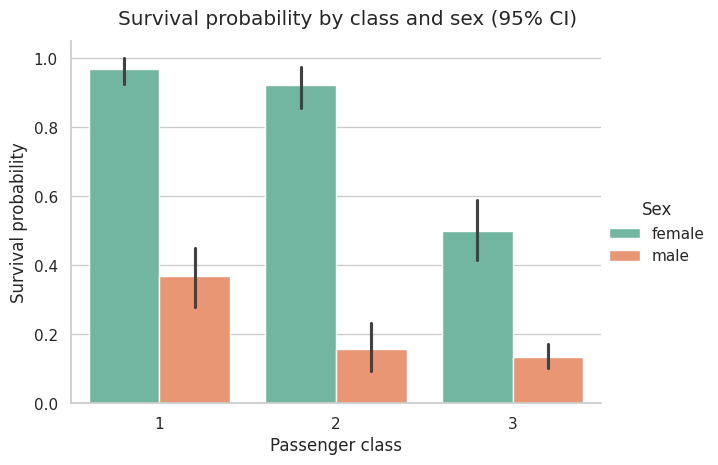

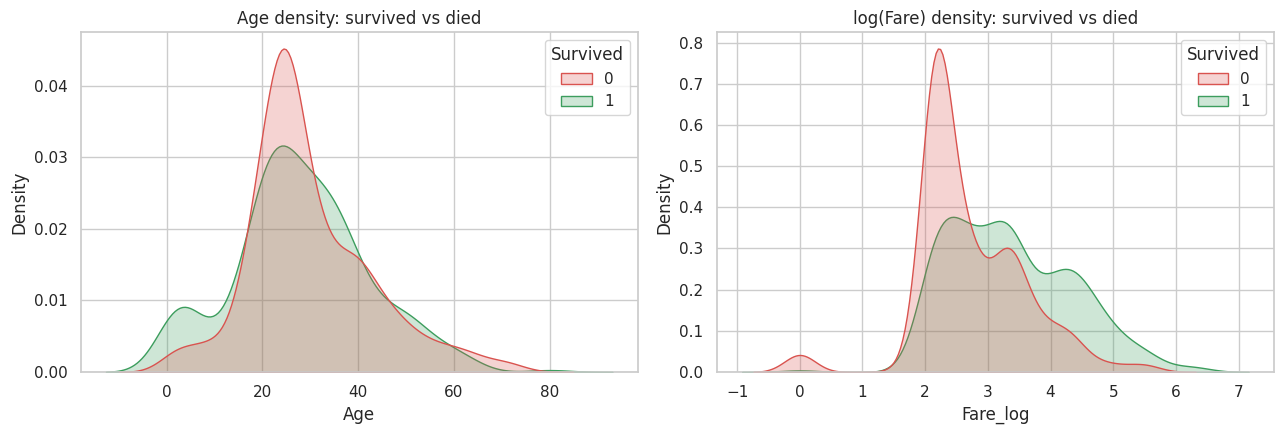

In [29]:
g = sns.catplot(data=df_clean, x="Pclass", y="Survived", hue="Sex", kind="bar", palette="Set2",
                height=4.5, aspect=1.4, errorbar=("ci", 95))
g.set_axis_labels("Passenger class", "Survival probability")
g.figure.suptitle("Survival probability by class and sex (95% CI)", y=1.03)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.kdeplot(data=df_clean, x="Age", hue="Survived", fill=True, common_norm=False, palette=SURV_COLORS, ax=axes[0])
axes[0].set_title("Age density: survived vs died")
sns.kdeplot(data=df_clean, x="Fare_log", hue="Survived", fill=True, common_norm=False, palette=SURV_COLORS, ax=axes[1])
axes[1].set_title("log(Fare) density: survived vs died")
plt.tight_layout(); plt.show()

In [37]:


def chi_square(col):
    ct = pd.crosstab(df_clean[col], df_clean["Survived"])

    chi2, p, dof, expected = stats.chi2_contingency(ct)

    return {
        "Attribute": col,
        "Test": "Chi-square",
        "Chi-square Statistic": round(chi2, 2),
        "df": dof,
        "p-value": p,
        "Significant (p<0.05)": "Yes" if p < 0.05 else "No"
    }


columns = [
    "Sex",
    "Pclass",
    "Title",
    "Deck",
    "Embarked",
    "AgeGroup",
    "FareBand",
    "FamilySize",
    "IsAlone",
    "SibSp",
    "Parch"
]

tests = pd.DataFrame([chi_square(c) for c in columns])

tests

,Attribute,Test,Chi-square Statistic,df,p-value,Significant (p<0.05)
0,Sex,Chi-square,260.72,1,1.197357e-58,Yes
1,Pclass,Chi-square,102.89,2,4.549252e-23,Yes
2,Title,Chi-square,288.12,4,3.957861e-61,Yes
3,Deck,Chi-square,99.16,8,6.326020e-18,Yes
4,Embarked,Chi-square,25.96,2,2.300863e-06,Yes
5,AgeGroup,Chi-square,15.52,4,3.736968e-03,Yes
6,FareBand,Chi-square,80.17,3,2.816617e-17,Yes
7,FamilySize,Chi-square,80.67,8,3.579669e-14,Yes
8,IsAlone,Chi-square,36.00,1,1.972654e-09,Yes
9,SibSp,Chi-square,37.27,6,1.558581e-06,Yes


Summary of Chi-square Analysis
Chi-square test was used to examine whether categorical features are associated with Survival.
The significance level was set at α = 0.05.
All tested categorical variables had p < 0.05, indicating a statistically significant association with survival.
Title and Sex showed the strongest associations based on Cramér’s V.
Pclass, Deck, FamilySize, and FareBand showed moderate associations.
SibSp, IsAlone, Parch, Embarked, and AgeGroup showed relatively weaker associations.
Therefore, the EDA indicates that passenger characteristics such as sex, title, class, and family-related variables were associated with survival outcomes.

---
## 5. Summary

### What was done
1. **Profiling (Task 1):** 12 attributes typed and summarised (mean, median, std, range, distinct values). `Cabin` (77% missing), `Age` (20%) and `Embarked` (2 rows) needed cleaning; no duplicate rows.
2. **Preprocessing (Task 4):** `Cabin` → `Deck` letter (`Unknown` kept as a category) and `Cabin` dropped; `Age` filled with the median of each (`Pclass`, `Sex`) group; `Embarked` filled with the mode; outliers inspected with the IQR rule and kept as genuine, with `Fare` log-transformed; new attributes `Title`, `FamilySize`, `IsAlone`, `AgeGroup`, `FareBand`; identifier/text columns dropped; binary + one-hot encoding and z-score normalisation for a final all-numeric table with **0 missing values**.
3. **Plots (Task 2):** histograms, boxplots, bar/pie charts, QQ plots (+ Shapiro-Wilk), scatter plots, correlation heatmap and pair plot. `Age` is roughly bell-shaped with a mild right skew, `Fare` is extremely right-skewed (skew 4.8, fixed to 0.4 by `log1p`), and `SibSp`/`Parch`/`FamilySize` are count variables concentrated at 0-1.
4. **Survival EDA (Task 3):** survival rates by every attribute, two-way interactions.

### Key findings: who was more likely to survive?
Overall, **342 of 891 passengers (38.4%) survived.**

| Factor | Higher survival | Lower survival |
|---|---|---|
| **Sex** (strongest) | Female **74.2%** | Male **18.9%** |
| **Title** | Mrs 79.4%, Miss 70.3%, Master (boys) 57.5% | Mr **15.7%** |
| **Passenger class** | 1st **63.0%**, 2nd 47.3% | 3rd **24.2%** |
| **Fare paid** | Top quartile 58.1% | Bottom quartile 19.7% |
| **Deck (cabin known)** | Decks B, D, E about 75% | Unknown cabin 30.0% |
| **Age group** | Children (0-12) **58.0%** | Seniors (60+) 22.7% |
| **Family size** | Travelling with 1-3 relatives (size 2-4): 55-72% | Alone 30.4%; family of 5+ : 0-33% |
| **Port of embarkation** | Cherbourg 55.4% | Southampton 33.7%, Queenstown 39.0% |

**Sex and class together** explain most of the pattern: women in 1st and 2nd class survived at **92-97%**, whereas 3rd-class women survived at only **50%**; men survived at **36.9% (1st), 15.7% (2nd) and 13.5% (3rd)**.

**Statistical evidence:** every categorical attribute tested is significantly associated with survival (chi-square p < 0.05).

### Conclusion
> **Passengers most likely to survive:** **women** (especially **1st- and 2nd-class women**, 85-98% survival), **children**, passengers who paid **higher fares / travelled in 1st class / had a known cabin on decks B-E**, and those travelling in **small families (2-4 people)**.
>
> **Passengers least likely to survive:** **adult men**, above all **2nd- and 3rd-class men (roughly 4-13%)**, **3rd-class passengers** in general, **solo travellers**, **very large families (5+)**, **low-fare passengers** and the elderly.

### Limitations
- Findings describe **association, not causation**; attributes are correlated (e.g. Fare, Pclass and Deck all proxy for wealth; Embarked is probably partly a class effect).
- ~20% of `Age` and ~77% of `Cabin` were imputed / encoded as "Unknown", so age- and deck-level results are less reliable than sex- and class-level ones.
- Some subgroups are small (e.g. deck T has 1 passenger, family sizes 8 and 11), so their rates are unstable.
- This is the 891-passenger training sample, not the whole ship (about 2,200 on board).